# Mandatory assignment 3

**GitHub repository:** https://github.com/Snorre1001/TECH2_Assignment03.git

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [1]:
import pandas as pd

# Load SCF_10pct.csv into a DataFrame
df = pd.read_csv("SCF_10pct.csv")

# Names of the columns and the number of their non-missing values
df.info()

print("\n")

# Columns into a list
columns = ["id", "year", "age", "educ", "stocks", "equity"]

# Dropping missing values per column, and report how many I dropped and how many remain.
for i in columns:
    len_before = len(df[i])
    df = df[df[i].isna() == False]
    len_after = len(df[i])
    print(f"{i}: dropped: {len_before - len_after} remaining: {len_after}")

# Keeping observations between 25 and 89,
# and reporting how many observations were dropped and how many remain.
len_age_before = len(df["age"])
df = df[(df["age"] >= 25) & (df["age"] <= 89)]
len_age_after = len(df["age"])
print(f"\nI dropped {len_age_before - len_age_after} observations. There are {len_age_after} observations remaining.")

# Making two new columns direct and overall. If the right side returns True, it will
# give 1 when multiplied with one, and 0 if it returns False.
df["direct"] = (df["stocks"] > 0) * 1
df["overall"] = (df["equity"] > 0) * 1

<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB


id: dropped: 0 remaining: 5808
year: dropped: 0 remaining: 5808
age: dropped: 0 remaining: 5808
educ: dropped: 16 remaining: 5792
stocks: dropped: 18 remaining: 5774
equity: dropped: 16 remaining: 5758

I dropped 326 observations. There are 5432 observations remaining.


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [2]:
# Takes in a sequence of ones and zeros, counts how many ones there are, and returns
# the share of ones in percentage. 
def participation_rate(indicator):
    count = 0
    for i in indicator:
        if i > 0:
            count += 1
    return (count / len(indicator)) * 100

# Applies my function to compute the direct and overall participation rates.
print(f"The direct participation rate with my function is {round(participation_rate(df['direct']), 1)}%")
print(f"The overall participation rate with my function is {round(participation_rate(df['overall']), 1)}%")

# Does the same, but with pandas's mean().
print(f"\nThe direct participation rate with the mean() method is {round(df['direct'].mean() * 100, 1)}%")
print(f"The overall participation rate with the mean() method is {round(df['overall'].mean() * 100, 1)}%")

The direct participation rate with my function is 17.0%
The overall participation rate with my function is 49.4%

The direct participation rate with the mean() method is 17.0%
The overall participation rate with the mean() method is 49.4%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

Direct rate for group 1: 4.4%, overall rate: 17.3%
Direct rate for group 2: 11.4%, overall rate: 39.9%
Direct rate for group 3: 13.5%, overall rate: 48.3%
Direct rate for group 4: 30.5%, overall rate: 73.5%


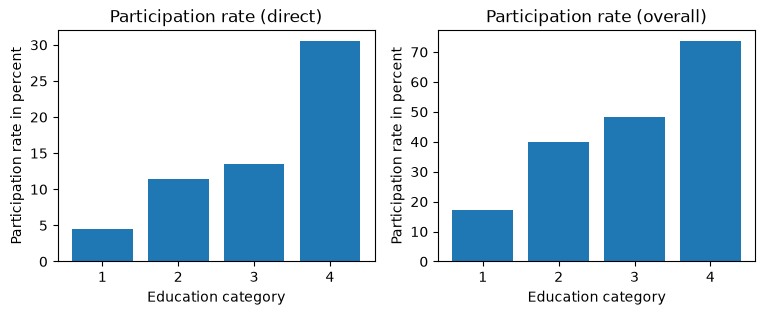

In [3]:
# Empty lists to store the rates for every educ category
direct_rates = []
overall_rates = []

# Looping over the educ categories and finding direct and overall participation rates
# which I put into the lists
for i in [1, 2, 3, 4]:
    degree = df[df["educ"] == i]
    direct_rate = participation_rate(degree["direct"])
    overall_rate = participation_rate(degree["overall"])
    direct_rates.append(direct_rate)
    overall_rates.append(overall_rate)
    print(f"Direct rate for group {i}: {round(direct_rate, 1)}%, overall rate: {round(overall_rate, 1)}%")


import matplotlib.pyplot as plt

# Making two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))

# Making a bar chart for the direct rates
ax1.bar([1, 2, 3, 4], direct_rates)
ax1.set_title("Participation rate (direct)")
ax1.set_xlabel("Education category")
ax1.set_ylabel("Participation rate in percent")

# Does the same thing for the overall rates
ax2.bar([1, 2, 3, 4], overall_rates)
ax2.set_title("Participation rate (overall)")
ax2.set_xlabel("Education category")
_ = ax2.set_ylabel("Participation rate in percent")


The participation rate increases with higher education levels. The direct participation rate more than doubles from people with some college to people with a bachelor's degree. The overall participation rate is around four times higher among people with a bachelor's degree than among people with no high school.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

Year 1989: Direct: 15.6% Overall: 31.6%
Year 1992: Direct: 18.3% Overall: 40.1%
Year 1995: Direct: 15.7% Overall: 45.9%
Year 1998: Direct: 19.9% Overall: 51.2%
Year 2001: Direct: 21.8% Overall: 57.0%
Year 2004: Direct: 18.9% Overall: 54.7%
Year 2007: Direct: 17.3% Overall: 56.5%
Year 2010: Direct: 17.4% Overall: 50.3%
Year 2013: Direct: 14.8% Overall: 49.9%
Year 2016: Direct: 12.3% Overall: 52.0%
Year 2019: Direct: 12.4% Overall: 49.8%
Year 2022: Direct: 19.2% Overall: 54.3%

The change in direct participation rates from 1989 to 2022 is 3.6 percentage points.
The change in overall participation rates from 1989 to 2022 is 22.8 percentage points.


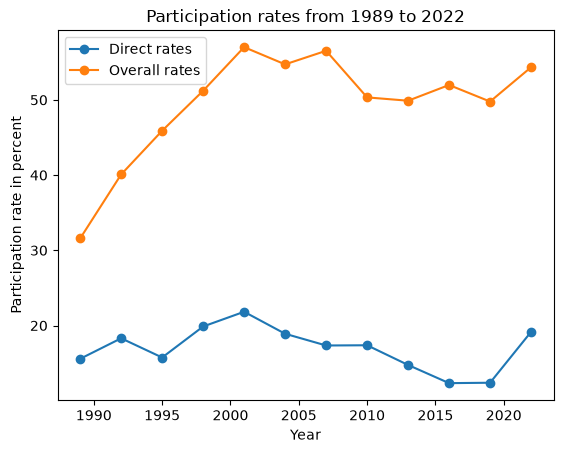

In [4]:
# Empty lists that store participation rates.
direct_rates_year = []
overall_rates_year = []

# Looping over the years the survey was done, finding the direct and overall participation rates,
# before I store them in the lists.
for i in range(1989, 2023, 3):
    year = df[df["year"] == i]
    direct_rate_year = participation_rate(year["direct"])
    overall_rate_year = participation_rate(year["overall"])
    direct_rates_year.append(direct_rate_year)
    overall_rates_year.append(overall_rate_year)
    print(f"Year {i}: Direct: {round(direct_rate_year, 1)}% Overall: {round(overall_rate_year, 1)}%")

# Making a line plot that shows both participation rates over the years between 1989 and 2022.
plt.plot(range(1989, 2023, 3), direct_rates_year, label="Direct rates", marker="o")
plt.plot(range(1989, 2023, 3), overall_rates_year, label="Overall rates", marker="o")
plt.ylabel("Participation rate in percent")
plt.xlabel("Year")
plt.title("Participation rates from 1989 to 2022")
_ = plt.legend()

# Finding the change from 1989 to 2022 in direct and overall participation rate in percentage points.
direct_change = direct_rates_year[-1] - direct_rates_year[0]
print(f"\nThe change in direct participation rates from 1989 to 2022 is {round(direct_change, 1)} percentage points.")
overall_change = overall_rates_year[-1] - overall_rates_year[0]
print(f"The change in overall participation rates from 1989 to 2022 is {round(overall_change, 1)} percentage points.")

The overall participation rate increased heavily from 32% in 1989 to 57% in 2001, before it flattened out. The direct participation rate is more stable, between 12% and 22%. They both peaked in 2001.

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I used Claude when I got stuck. It explained the tasks and gave me hints on what to do next. I also used it to check my English in the notes and written answers.